# Predicting Inorganic Fertilizer Adoption on Rwandan Farm Plots
## Notebook 2 — Traditional Machine Learning (scikit-learn)

This notebook trains and compares four families of traditional classifiers on the plot-level table built in notebook 1:

| Model | Why it is included |
|---|---|
| **Logistic Regression** | Linear, interpretable baseline. Shows how far a simple additive model gets. |
| **Random Forest** | Bagged decision trees. Captures interactions (e.g. *crop × district*) without feature engineering. |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Boosted trees, usually the strongest family on tabular data. The histogram version is scikit-learn's fast implementation for datasets of this size. |
| **Support Vector Machine** (RBF kernel) | A non-linear margin-based method from a different family than trees. |

**Experiments:**
1. Baselines and default models, with 5-fold cross-validation grouped by farmer
2. Handling class imbalance (class weights)
3. Hyperparameter tuning (randomized / grid search)
4. Feature engineering and feature-group ablation
5. Decision-threshold optimisation
6. Final test-set evaluation, learning curves, feature importance and error analysis

**Rule for the test set:** all model choices are made with cross-validation on the training set and checks on the **validation** set. The **test** set is used only once, in Section 7.

### Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold, cross_validate, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report
from scipy.stats import loguniform, randint, uniform

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import load_model_table, add_farmer_features, build_preprocessor, FARMER_FEATURES
from src.evaluation import (set_style, evaluate, scores_of, best_f1_threshold, plot_confusion,
                            plot_roc_pr, plot_learning_curve, MODEL_CLR, CLASS_CLR, MUTED)

SEED = 42
FIG = ROOT / "figures"; MODELS = ROOT / "models"; RESULTS = ROOT / "results"
for p in (FIG, MODELS, RESULTS): p.mkdir(exist_ok=True)
set_style()
warnings.filterwarnings("ignore", category=UserWarning); warnings.filterwarnings("ignore", category=FutureWarning)

### 1. Load data and define the splits
We load the table and the farmer-grouped split labels created in notebook 1, then add three **engineered farmer-level features** (defined in `src/features.py`):

- `log_farmer_n_plots`: how many plots the farmer manages this season
- `log_farmer_total_area`: total area the farmer cultivates this season
- `plot_share_of_farm`: this plot's share of that area

These describe the plot *in the context of the whole farm*. They are computed from plot areas only, never from the target. Section 4 tests whether they help.

In [2]:
df, spec = load_model_table(ROOT / "data" / "processed")
df = add_farmer_features(df)
TARGET = spec["target"]
CAT, NUM, BIN = spec["categorical"], spec["numeric"], spec["binary"]
NUM_FE = NUM + FARMER_FEATURES          # numeric features including the engineered ones

train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = train[TARGET].values, val[TARGET].values, test[TARGET].values
groups_tr = train["farmer_id"].values
cv = GroupKFold(n_splits=5)

print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")
print(f"features: {len(CAT)} categorical, {len(NUM_FE)} numeric, {len(BIN)} binary")

train 23,127 | val 5,056 | test 5,045
features: 6 categorical, 8 numeric, 31 binary


### 2. Preprocessing pipeline
Each model is wrapped in a scikit-learn `Pipeline` together with a `ColumnTransformer` that:
- **Categoricals** (province, district, stratum, farmer type, gender, erosion degree): fills missing values with `"Unknown"` and **one-hot encodes** them. Unseen categories at prediction time are ignored rather than causing an error.
- **Numerics**: **median imputation** and **standardisation** (mean 0, standard deviation 1). Scaling matters for Logistic Regression and the SVM, and has no effect on the tree models.
- **Binary flags**: passed through unchanged.

Because preprocessing sits *inside* the pipeline, the imputation medians and scaling statistics are recomputed on the training folds of every cross-validation split. They never see validation or test data, which avoids preprocessing leakage.

In [3]:
def make_pipe(model, cat=CAT, num=NUM_FE, binary=BIN):
    return Pipeline([("pre", build_preprocessor(cat, num, binary)), ("model", model)])

def X_of(frame, cat=CAT, num=NUM_FE, binary=BIN):
    return frame[cat + num + binary]

X_tr, X_va, X_te = X_of(train), X_of(val), X_of(test)
print("Columns after one-hot encoding:", make_pipe(LogisticRegression()).named_steps["pre"].fit(X_tr).transform(X_tr[:5]).shape[1])

Columns after one-hot encoding: 92


**Evaluation metrics.** Only about 28% of plots are positive, so we report:
- **ROC-AUC**: how well the model *ranks* fertilized plots above unfertilized ones, independent of any threshold. This is the **primary selection metric**.
- **PR-AUC (average precision)**: like ROC-AUC, but focused on the positive class. More informative under imbalance (a no-skill model scores 0.28, not 0.5).
- **F1, precision, recall**: performance of the actual yes/no predictions.
- **Balanced accuracy**: the average of recall on each class.

Plain accuracy is shown for comparison only. A model that always predicts "No" already gets 72% accuracy.

### 3. Experiment 1: baselines and default models
We start with a **majority-class dummy** (always predicts "No") to set a floor, then train each of the four models with default settings. Each model is scored with **5-fold `GroupKFold`** on the training set, so a farmer's plots never appear in both the training and the scoring fold of the same split.

The SVM is the slowest model here (about 30–60 s per fit), because kernel SVM training time grows roughly with the square of the number of rows.

In [4]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1",
           "precision": "precision", "recall": "recall", "balanced_acc": "balanced_accuracy"}

def cv_eval(name, pipe, X=X_tr, n_jobs=-1):
    t = time.time()
    r = cross_validate(pipe, X, y_tr, groups=groups_tr, cv=cv, scoring=SCORING, n_jobs=n_jobs)
    row = {"model": name, **{k: r[f"test_{k}"].mean() for k in SCORING},
           "roc_auc_sd": r["test_roc_auc"].std(), "fit_seconds": r["fit_time"].mean()}
    print(f"{name:32s} ROC-AUC {row['roc_auc']:.4f} ± {row['roc_auc_sd']:.4f} | F1 {row['f1']:.3f} | {time.time() - t:.0f}s")
    return row

default_models = {
    "Majority class (dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    "Gradient Boosting (HGB)": HistGradientBoostingClassifier(random_state=SEED),
    "SVM (RBF)": SVC(random_state=SEED),
}
exp1 = pd.DataFrame([cv_eval(n, make_pipe(m)) for n, m in default_models.items()]).set_index("model")
exp1.round(4)

Majority class (dummy)           ROC-AUC 0.5000 ± 0.0000 | F1 0.000 | 2s


Logistic Regression              ROC-AUC 0.8809 ± 0.0027 | F1 0.664 | 2s


Random Forest                    ROC-AUC 0.8947 ± 0.0047 | F1 0.686 | 27s


Gradient Boosting (HGB)          ROC-AUC 0.8965 ± 0.0032 | F1 0.696 | 7s


SVM (RBF)                        ROC-AUC 0.8889 ± 0.0042 | F1 0.684 | 70s


,roc_auc,pr_auc,f1,precision,recall,balanced_acc,roc_auc_sd,fit_seconds
model,,,,,,,,
Majority class (dummy),0.5000,0.2766,0.0000,0.0000,0.0000,0.5000,0.0000,0.1376
Logistic Regression,0.8809,0.7476,0.6637,0.7488,0.5962,0.7599,0.0027,0.4766
Random Forest,0.8947,0.7879,0.6864,0.7698,0.6193,0.7743,0.0047,8.8213
Gradient Boosting (HGB),0.8965,0.7907,0.6964,0.7551,0.6464,0.7832,0.0032,1.8723
SVM (RBF),0.8889,0.7718,0.6841,0.7609,0.6217,0.7735,0.0042,17.1126


> Based on the output All 4 models are far better than the dummy. But recall is only about 60%: they miss about 40% of fertilizer users.

### 4. Experiment 2: handling class imbalance
With a 28/72 split, the default models optimise overall accuracy and are biased towards predicting "No". We compare two options:
- **No adjustment** (Experiment 1)
- **`class_weight="balanced"`**: errors on the minority class are weighted about 2.6× more heavily during training

We do not oversample with SMOTE. With many one-hot categorical features, synthetic interpolated points (e.g. "0.4 of district Musanze") are not meaningful, and class weights achieve the same rebalancing without inventing data.

In [5]:
balanced_models = {
    "Logistic Regression + balanced": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest + balanced": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, class_weight="balanced"),
    "Gradient Boosting (HGB) + balanced": HistGradientBoostingClassifier(random_state=SEED, class_weight="balanced"),
    "SVM (RBF) + balanced": SVC(random_state=SEED, class_weight="balanced"),
}
exp2 = pd.DataFrame([cv_eval(n, make_pipe(m)) for n, m in balanced_models.items()]).set_index("model")
cmp_cols = ["roc_auc", "pr_auc", "f1", "precision", "recall", "balanced_acc"]
pd.concat([exp1.drop(index="Majority class (dummy)")[cmp_cols], exp2[cmp_cols]]).sort_index().round(3)

Logistic Regression + balanced   ROC-AUC 0.8818 ± 0.0027 | F1 0.699 | 2s


Random Forest + balanced         ROC-AUC 0.8953 ± 0.0043 | F1 0.719 | 26s


Gradient Boosting (HGB) + balanced ROC-AUC 0.8969 ± 0.0029 | F1 0.716 | 8s


SVM (RBF) + balanced             ROC-AUC 0.8909 ± 0.0028 | F1 0.713 | 90s


,roc_auc,pr_auc,f1,precision,recall,balanced_acc
model,,,,,,
Gradient Boosting (HGB),0.896,0.791,0.696,0.755,0.646,0.783
Gradient Boosting (HGB) + balanced,0.897,0.791,0.716,0.648,0.800,0.817
Logistic Regression,0.881,0.748,0.664,0.749,0.596,0.760
Logistic Regression + balanced,0.882,0.744,0.699,0.622,0.798,0.806
Random Forest,0.895,0.788,0.686,0.770,0.619,0.774
Random Forest + balanced,0.895,0.786,0.719,0.707,0.732,0.808
SVM (RBF),0.889,0.772,0.684,0.761,0.622,0.773
SVM (RBF) + balanced,0.891,0.759,0.713,0.642,0.801,0.815


> Recall jumped a lot: now about 80% of fertilizer users are found. ROC-AUC barely moved. ROC-AUC measures ranking (does the model put Yes plots above No plots?). Weights don’t change the ranking much; they just shift where the model draws the line. Precision went down a bit: more false alarms. That’s the trade-off.

### 5. Experiment 3: hyperparameter tuning
Each model is tuned with **randomized search** (grid search for the SVM), using **3-fold `GroupKFold`** cross-validation on the training set and optimising **ROC-AUC**. Three folds instead of five keep the run time manageable on a laptop. The search spaces:

| Model | Hyperparameters searched |
|---|---|
| Logistic Regression | `C` (inverse regularisation strength, 10⁻³–10²), L1 vs L2 penalty (`l1_ratio` = 1 or 0) |
| Random Forest | number of trees, `max_depth`, `min_samples_leaf`, `max_features` |
| Gradient Boosting | `learning_rate`, `max_iter` (with early stopping), `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` |
| SVM (RBF) | `C` × `gamma` grid |

**SVM optimisation:** a full grid on 23,000 rows would take more than an hour, so the SVM grid is searched on a random **6,000-plot subsample of farmers**. The best setting is then refitted on the full training set. This is a standard practical compromise for kernel methods. We note it in the report as a limitation.

In [6]:
cv3 = GroupKFold(n_splits=3)
searches, tuned = {}, {}

def run_search(name, search):
    t = time.time()
    search.fit(X_tr if name != "SVM (RBF)" else X_svm, y_tr if name != "SVM (RBF)" else y_svm,
               groups=groups_tr if name != "SVM (RBF)" else g_svm)
    searches[name] = search
    print(f"{name:24s} best CV ROC-AUC {search.best_score_:.4f} in {time.time() - t:.0f}s")
    print("   best params:", {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v)
                               for k, v in search.best_params_.items()})

# --- Logistic Regression
run_search("Logistic Regression", RandomizedSearchCV(
    make_pipe(LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=3000)),
    {"model__C": loguniform(1e-3, 1e2), "model__l1_ratio": [0, 1]},   # l1_ratio 0 = L2 (ridge), 1 = L1 (lasso)
    n_iter=20, scoring="roc_auc", cv=cv3, random_state=SEED, n_jobs=-1))

# --- Random Forest
run_search("Random Forest", RandomizedSearchCV(
    make_pipe(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)),
    {"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 10, 16, 24, 32],
     "model__min_samples_leaf": [1, 2, 5, 10, 20], "model__max_features": ["sqrt", 0.2, 0.35, 0.5]},
    n_iter=15, scoring="roc_auc", cv=cv3, random_state=SEED, n_jobs=1))

# --- Gradient Boosting
run_search("Gradient Boosting (HGB)", RandomizedSearchCV(
    make_pipe(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED,
                                             early_stopping=True, validation_fraction=0.1, n_iter_no_change=30)),
    {"model__learning_rate": loguniform(0.02, 0.3), "model__max_iter": [300, 600, 1000],
     "model__max_leaf_nodes": [15, 31, 63, 127], "model__min_samples_leaf": randint(10, 120),
     "model__l2_regularization": loguniform(1e-3, 10)},
    n_iter=25, scoring="roc_auc", cv=cv3, random_state=SEED, n_jobs=-1))

Logistic Regression      best CV ROC-AUC 0.8816 in 40s
   best params: {'C': np.float64(1.2357), 'l1_ratio': 1}


Random Forest            best CV ROC-AUC 0.8953 in 418s
   best params: {'n_estimators': 600, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 24}


Gradient Boosting (HGB)  best CV ROC-AUC 0.8952 in 157s
   best params: {'l2_regularization': np.float64(0.0774), 'learning_rate': np.float64(0.0276), 'max_iter': 600, 'max_leaf_nodes': 63, 'min_samples_leaf': 10}


In [7]:
# --- SVM: grid search on a farmer-grouped subsample
rng = np.random.default_rng(SEED)
farmers = train["farmer_id"].unique()
keep = set(rng.choice(farmers, size=int(len(farmers) * 6000 / len(train)), replace=False))
m_svm = train["farmer_id"].isin(keep).values
X_svm, y_svm, g_svm = X_tr[m_svm], y_tr[m_svm], groups_tr[m_svm]
print(f"SVM tuning subsample: {m_svm.sum():,} plots")

run_search("SVM (RBF)", GridSearchCV(
    make_pipe(SVC(class_weight="balanced", random_state=SEED)),
    {"model__C": [0.1, 0.3, 1, 3, 10], "model__gamma": ["scale", 0.003, 0.01, 0.03, 0.1]},
    scoring="roc_auc", cv=cv3, n_jobs=-1))

SVM tuning subsample: 5,953 plots


SVM (RBF)                best CV ROC-AUC 0.8720 in 51s
   best params: {'C': 1, 'gamma': 0.03}


Visualising the SVM grid shows *how sensitive* the model is to its two hyperparameters: `C` (how hard it tries to classify every training point correctly) and `gamma` (how local each support vector's influence is).

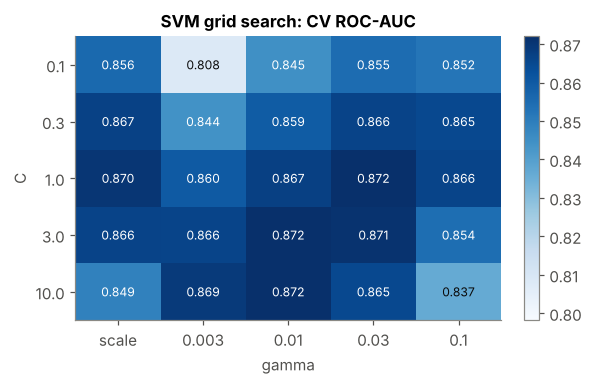

In [8]:
r = pd.DataFrame(searches["SVM (RBF)"].cv_results_)
heat = r.pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score", aggfunc="first")
heat = heat[["scale", 0.003, 0.01, 0.03, 0.1]]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=heat.values.min() - 0.01)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        mid = (heat.values.min() + heat.values.max()) / 2
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8, color="white" if v > mid else "#0b0b0b")
ax.set_xticks(range(heat.shape[1]), [str(c) for c in heat.columns]); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("SVM grid search: CV ROC-AUC"); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout()
plt.savefig(FIG / "07_svm_grid.png", bbox_inches="tight"); plt.show()

Now the best configuration of each model is **refitted on the full training set** and compared with its default version **on the validation set**.

In [9]:
default_balanced = {"Logistic Regression": balanced_models["Logistic Regression + balanced"],
                    "Random Forest": balanced_models["Random Forest + balanced"],
                    "Gradient Boosting (HGB)": balanced_models["Gradient Boosting (HGB) + balanced"],
                    "SVM (RBF)": balanced_models["SVM (RBF) + balanced"]}
rows = []
for name, search in searches.items():
    t = time.time()
    best = search.best_estimator_ if name != "SVM (RBF)" else make_pipe(SVC(class_weight="balanced", random_state=SEED)).set_params(**search.best_params_)
    best.fit(X_tr, y_tr); tuned[name] = best
    base = make_pipe(default_balanced[name]).fit(X_tr, y_tr)
    rows.append({"model": name, "version": "default", **evaluate(base, X_va, y_va)})
    rows.append({"model": name, "version": "tuned", **evaluate(best, X_va, y_va)})
    print(f"{name} refit done in {time.time() - t:.0f}s")
exp3 = pd.DataFrame(rows).set_index(["model", "version"])
exp3[cmp_cols].round(4)

Logistic Regression refit done in 8s


Random Forest refit done in 16s


Gradient Boosting (HGB) refit done in 9s


SVM (RBF) refit done in 91s


roc_auc  pr_auc      f1  precision  recall  \
model                   version                                               
Logistic Regression     default   0.8800  0.7314  0.6973     0.6157  0.8039   
                        tuned     0.8804  0.7318  0.6975     0.6160  0.8039   
Random Forest           default   0.8910  0.7713  0.7148     0.6906  0.7407   
                        tuned     0.8924  0.7738  0.7212     0.6870  0.7589   
Gradient Boosting (HGB) default   0.8937  0.7809  0.7132     0.6399  0.8054   
                        tuned     0.8928  0.7774  0.7164     0.6470  0.8025   
SVM (RBF)               default   0.8899  0.7473  0.7141     0.6386  0.8097   
                        tuned     0.8890  0.7411  0.7071     0.6285  0.8083   

                                 balanced_acc  
model                   version                
Logistic Regression     default        0.8080  
                        tuned          0.8082  
Random Forest           default        0.8083  
                        tuned          0.8148  
Gradient Boosting (HGB) default        0.8179  
                        tuned          0.8193  
SVM (RBF)               default        0.8191  
                        tuned          0.8147

> sfter comparing both best tuned version and default version tuning **barely helped**
> Logistic Regression	**0.8800 → 0.8803**
> Random Forest	**0.8910 → 0.8924**
> Gradient Boosting	**0.8937 → 0.8928** (slightly worse)
> SVM	**0.8899 → 0.8890**

### 6. Experiment 4: feature engineering and feature-group ablation
Using the tuned **Gradient Boosting** configuration (fast to retrain), we add or remove one group of features at a time and measure validation performance. This answers two questions: *which kinds of information matter most?* and *did our engineered features help?*

| Feature set | What changes |
|---|---|
| Full model | All features including the engineered farmer-level ones |
| − engineered farmer features | Drop `log_farmer_n_plots`, `log_farmer_total_area`, `plot_share_of_farm` |
| − location | Drop province, district, stratum |
| − crops | Drop all `crop_*` indicators |
| − farming practices | Drop organic fertilizer, improved seed, consolidation, erosion, machinery, irrigation |
| − farmer demographics | Drop gender, age, farmer type |
| + pesticide (leakage check) | Add pesticide use on the plot, the near-proxy we excluded in notebook 1 |

In [10]:
crop_cols = [c for c in BIN if c.startswith("crop_")]
practice_bin = ["organic_fert_any_plot", "organic_fert_plot", "improved_seed_plot", "land_consolidation",
                "anti_erosion_plot", "mechanical_any_plot", "tractor_plot", "other_machine_plot", "irrigated_plot"]
hgb_params = {k.replace("model__", ""): v for k, v in searches["Gradient Boosting (HGB)"].best_params_.items()}

def ablation(name, cat=CAT, num=NUM_FE, binary=BIN):
    model = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, early_stopping=True,
                                           validation_fraction=0.1, n_iter_no_change=30, **hgb_params)
    p = make_pipe(model, cat, num, binary).fit(X_of(train, cat, num, binary), y_tr)
    return {"feature set": name, "n_features_raw": len(cat) + len(num) + len(binary),
            **evaluate(p, X_of(val, cat, num, binary), y_va)}

minus = lambda lst, drop: [c for c in lst if c not in drop]
exp4 = pd.DataFrame([
    ablation("Full model"),
    ablation("− engineered farmer features", num=NUM),
    ablation("− location", cat=minus(CAT, ["province", "district", "stratum"])),
    ablation("− crops", binary=minus(BIN, crop_cols)),
    ablation("− farming practices", cat=minus(CAT, ["erosion_degree"]), num=minus(NUM_FE, ["log_hired_labour"]), binary=minus(BIN, practice_bin)),
    ablation("− farmer demographics", cat=minus(CAT, ["gender", "farmer_type"]), num=minus(NUM_FE, ["age"])),
    ablation("+ pesticide (leakage check)", binary=BIN + ["pesticide_plot"]),
]).set_index("feature set")
exp4["Δ ROC-AUC vs full"] = exp4["roc_auc"] - exp4.loc["Full model", "roc_auc"]
exp4[["n_features_raw", "roc_auc", "Δ ROC-AUC vs full", "pr_auc", "f1"]].round(4)

,n_features_raw,roc_auc,Δ ROC-AUC vs full,pr_auc,f1
feature set,,,,,
Full model,45,0.8928,0.0000,0.7774,0.7164
− engineered farmer features,42,0.8934,0.0005,0.7802,0.7139
− location,42,0.8742,-0.0186,0.7430,0.6792
− crops,24,0.8499,-0.0430,0.7032,0.6560
− farming practices,34,0.8553,-0.0375,0.7123,0.6601
− farmer demographics,42,0.8926,-0.0003,0.7765,0.7203
+ pesticide (leakage check),46,0.9032,0.0104,0.8015,0.7242


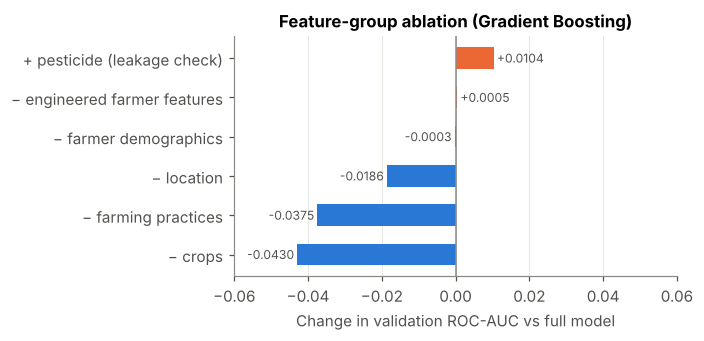

In [11]:
d = exp4["Δ ROC-AUC vs full"].drop("Full model").sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(d.index, d.values, color=[CLASS_CLR["No"] if v < 0 else CLASS_CLR["Yes"] for v in d.values], height=0.55)
for i, v in enumerate(d.values):
    ax.text(v + (0.0008 if v >= 0 else -0.0008), i, f"{v:+.4f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=MUTED)
ax.axvline(0, color="#8a8984", lw=1)
lim = max(abs(d.values)) * 1.4; ax.set_xlim(-lim, lim)
ax.set_xlabel("Change in validation ROC-AUC vs full model"); ax.set_title("Feature-group ablation (Gradient Boosting)")
ax.grid(axis="y", visible=False); plt.tight_layout()
plt.savefig(FIG / "08_ablation.png", bbox_inches="tight"); plt.show()

> as we remove some features some just herts the model others don't like removing crops seems to hurt more which is understandable it's crops in agriculture they are the main character. but as we can see the graph adding some feature also shows that it made our model better like adding pestcide and as for our engineered features there is a few unnoticable change

### 7. Model selection, threshold tuning and final test evaluation
The final model is the tuned model with the **highest validation ROC-AUC**.

**Threshold optimisation.** Classifiers predict "Yes" when the score is above a cut-off (0.5 by default). We choose the cut-off that **maximises F1 on the validation set**, then apply that fixed threshold to the test set.

In [12]:
val_auc = {n: evaluate(m, X_va, y_va)["roc_auc"] for n, m in tuned.items()}
BEST = max(val_auc, key=val_auc.get)
best_model = tuned[BEST]
print("Validation ROC-AUC of tuned models:", {k: round(v, 4) for k, v in val_auc.items()})
print("Selected model:", BEST)

thr, f1_at_thr = best_f1_threshold(y_va, scores_of(best_model, X_va))
default_rule = evaluate(best_model, X_va, y_va); tuned_rule = evaluate(best_model, X_va, y_va, threshold=thr)
print(f"\nBest-F1 threshold on validation: {thr:.3f}")
pd.DataFrame({"default threshold": default_rule, f"threshold = {thr:.2f}": tuned_rule}).T[cmp_cols].round(4)

Validation ROC-AUC of tuned models: {'Logistic Regression': 0.8804, 'Random Forest': 0.8924, 'Gradient Boosting (HGB)': 0.8928, 'SVM (RBF)': 0.889}
Selected model: Gradient Boosting (HGB)



Best-F1 threshold on validation: 0.572


,roc_auc,pr_auc,f1,precision,recall,balanced_acc
default threshold,0.8928,0.7774,0.7164,0.6470,0.8025,0.8193
threshold = 0.57,0.8928,0.7774,0.7207,0.6809,0.7654,0.8156


#### 7a. Test-set results for all tuned models
These numbers are the headline results for the report. The selected model's test score is an unbiased estimate, because the test set played no part in any decision. The other models are shown on the same test set for comparison.

In [13]:
test_rows, test_scores = [], {}
for name, m in tuned.items():
    test_scores[name] = scores_of(m, X_te)
    t = thr if name == BEST else None
    test_rows.append({"model": name + (" ★ (tuned threshold)" if name == BEST else ""), **evaluate(m, X_te, y_te, threshold=t)})
test_table = pd.DataFrame(test_rows).set_index("model")
test_table[cmp_cols + ["accuracy"]].round(4)

,roc_auc,pr_auc,f1,precision,recall,balanced_acc,accuracy
model,,,,,,,
Logistic Regression,0.8775,0.7187,0.6946,0.6234,0.7842,0.8016,0.8093
Random Forest,0.8898,0.7631,0.7089,0.6861,0.7333,0.8026,0.8335
Gradient Boosting (HGB) ★ (tuned threshold),0.8916,0.7658,0.7124,0.6774,0.7513,0.8073,0.8323
SVM (RBF),0.8859,0.7247,0.7144,0.6403,0.8079,0.8172,0.8214


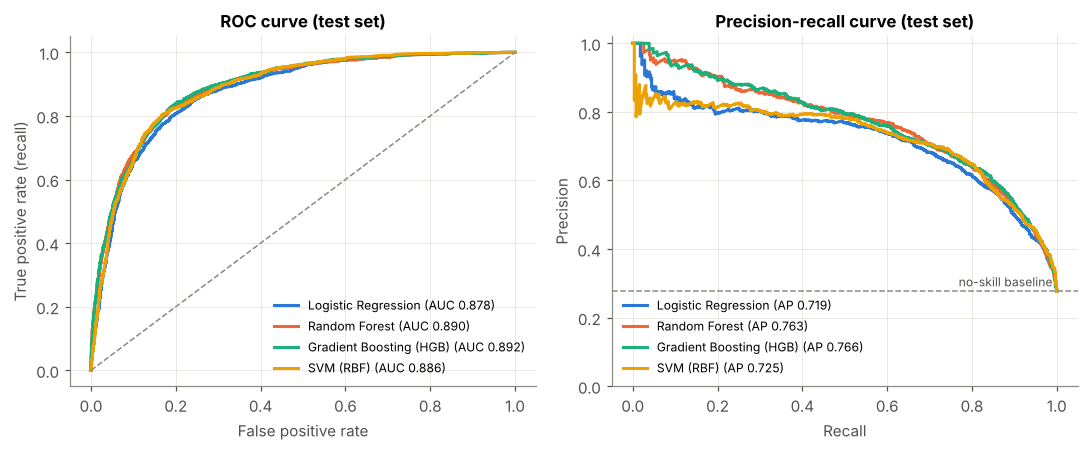

In [14]:
plot_roc_pr(test_scores, y_te, title_suffix=" (test set)", fname=FIG / "09_ml_roc_pr_test.png")

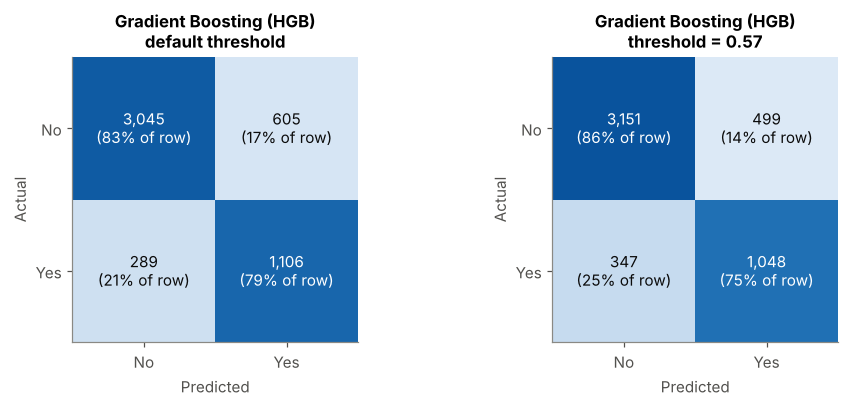

               precision    recall  f1-score   support

No fertilizer      0.901     0.863     0.882      3650
   Fertilizer      0.677     0.751     0.712      1395

     accuracy                          0.832      5045
    macro avg      0.789     0.807     0.797      5045
 weighted avg      0.839     0.832     0.835      5045



In [15]:
y_pred_te = (scores_of(best_model, X_te) >= thr).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
plot_confusion(y_te, best_model.predict(X_te), f"{BEST}\ndefault threshold", axes[0])
plot_confusion(y_te, y_pred_te, f"{BEST}\nthreshold = {thr:.2f}", axes[1])
plt.tight_layout(); plt.savefig(FIG / "10_ml_confusion_test.png", bbox_inches="tight"); plt.show()
print(classification_report(y_te, y_pred_te, target_names=["No fertilizer", "Fertilizer"], digits=3))

> Our model using a default threshold was able to detect Actual No 3045 which is 83% accuracy and only missed 605 which is 17% and actual yes amongest 1395  the model corectly found 1106 which is 79% and only missed 289 which counts to 21%
>
> the value change when we increased the threshold to 0.57 we were able to get actual no 3151  this is the increase of +3%  and misses 499 plots the decrease of -3% but on actual yes the model predicts 1048 a -4% decrease and missed 347 which is +4% this shows that our model ilikely to detect more plot without fertilizer than the ones with this is because in our dataset we had a few plots with fertilizers in **01_data_preparation_and_eda** we found that we had 27.8% yes and 72.4% No

### 8. Learning curves
A learning curve trains the model on increasing amounts of data and plots training vs cross-validation ROC-AUC:
- A **large, persistent gap** between the curves means **high variance (overfitting)**. More data or more regularisation would help.
- **Both curves low and close together** means **high bias (underfitting)**. The model or the features are too simple.
- **A validation curve still rising** at the right edge means more data would help.

We compare the selected model with Logistic Regression to contrast a flexible model with a simple one.

Gradient Boosting (HGB): 83s


Logistic Regression: 32s


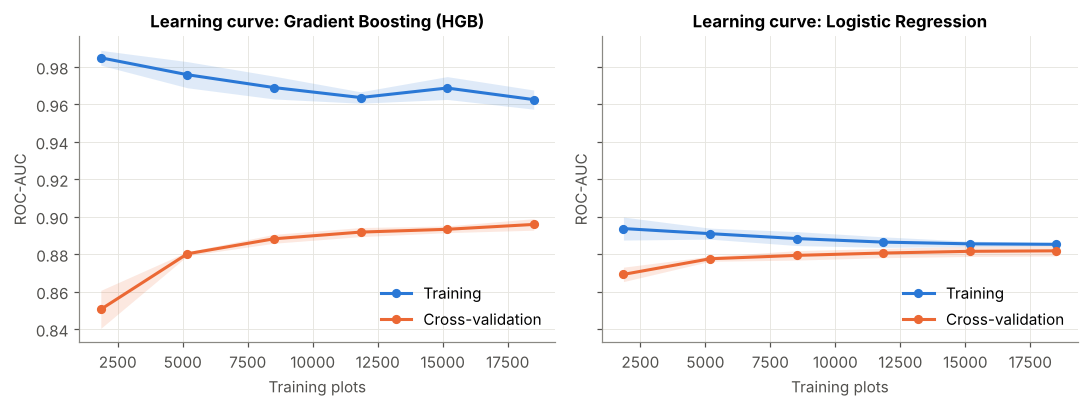

Gradient Boosting (HGB)  final train 0.9626 | final CV 0.8959 | gap 0.0667
Logistic Regression      final train 0.8853 | final CV 0.8818 | gap 0.0035


In [16]:
sizes = np.linspace(0.1, 1.0, 6)
lc = {}
for name in dict.fromkeys([BEST, "Logistic Regression"]):
    t = time.time()
    model = tuned[name] if name != "SVM (RBF)" else tuned[name]
    lc[name] = learning_curve(model, X_tr, y_tr, groups=groups_tr, cv=cv, train_sizes=sizes,
                              scoring="roc_auc", n_jobs=-1, shuffle=True, random_state=SEED)
    print(f"{name}: {time.time() - t:.0f}s")

fig, axes = plt.subplots(1, len(lc), figsize=(5 * len(lc), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, (name, (n, tr_s, va_s)) in zip(axes, lc.items()):
    plot_learning_curve(n, tr_s, va_s, f"Learning curve: {name}", ax)
plt.tight_layout(); plt.savefig(FIG / "11_ml_learning_curves.png", bbox_inches="tight"); plt.show()
for name, (n, tr_s, va_s) in lc.items():
    print(f"{name:24s} final train {tr_s[-1].mean():.4f} | final CV {va_s[-1].mean():.4f} | gap {tr_s[-1].mean() - va_s[-1].mean():.4f}")

>Gradient Boosting: training 0.9626, validation 0.8959, gap 0.066, so Gradient Boosting is more flexible it learns more (higher score) but also memorises a gap 0.066, which means mild overfitting. But The gap shrinks as data grows, and the validation line is still rising.
Logistic Regression: the lines are close to each other and are flat,
Adding 2021/2022 data would probably increase the GBoost.


### 9. Which features drive the predictions? (Permutation importance)
**Permutation importance** shuffles one *original* column at a time in the validation set and measures how much ROC-AUC drops. It works for any model, and because it acts on the raw columns (before one-hot encoding), a variable like `district` is measured as a whole.

computed in 22s


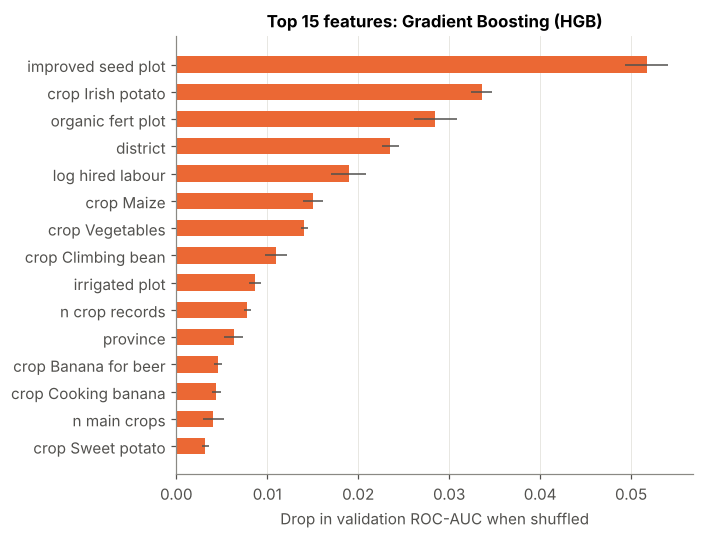

,feature,mean,sd
17,improved_seed_plot,0.0517,0.0024
33,crop_Irish_potato,0.0336,0.0012
16,organic_fert_plot,0.0285,0.0024
1,district,0.0235,0.0009
10,log_hired_labour,0.0190,0.0019
34,crop_Maize,0.0151,0.0011
43,crop_Vegetables,0.0141,0.0004
27,crop_Climbing_bean,0.0110,0.0012
23,irrigated_plot,0.0087,0.0007
9,n_crop_records,0.0078,0.0004


In [17]:
t = time.time()
pi = permutation_importance(best_model, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_va.columns, "mean": pi.importances_mean, "sd": pi.importances_std}).sort_values("mean", ascending=False)
print(f"computed in {time.time() - t:.0f}s")
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(top["feature"].str.replace("_", " "), top["mean"], xerr=top["sd"], color=CLASS_CLR["Yes"], height=0.6,
        error_kw={"ecolor": MUTED, "lw": 1})
ax.set_xlabel("Drop in validation ROC-AUC when shuffled"); ax.set_title(f"Top 15 features: {BEST}")
ax.grid(axis="y", visible=False); plt.tight_layout()
plt.savefig(FIG / "12_ml_permutation_importance.png", bbox_inches="tight"); plt.show()
imp.head(15).round(4)

> Based on Permutation importance Graph improved_seed_plot and it agrees with my EDA  by
>
> **Improved seed: 60% vs 19% adoption in the EDA → #1 here**
> 
>**Irish potato: 68% adoption in the EDA → #2 here**
> 
> **Organic fertilizer: 39% vs 13.5% in the EDA → #3 here**
> 
> **District: a big range (10%–59%) in the EDA → #4 here**
>
> why these 3 this is because of agronomic policy in Rwanda The Improved seed and fertilizer are often distributed together through Rwanda’s Crop Intensification Programme (CIP) as an input package. and A farmer who pays for improved seed has already decided to invest in a better harvest, so fertilizer is the natural next step. Improved seed without fertilizer often doesn’t reach its full potential.

### 10. Error analysis
Where does the final model fail? We compare error rates on the **test set** across provinces, seasons and farmer types, and look at which kinds of plots produce the most false negatives (missed fertilizer users) and false positives.

In [18]:
ea = test[["province", "season", "farmer_type", "district"]].copy()
ea["y"] = y_te; ea["pred"] = y_pred_te
ea["fn"] = (ea.y == 1) & (ea.pred == 0); ea["fp"] = (ea.y == 0) & (ea.pred == 1)

def err_table(col):
    g = ea.groupby(col)
    out = pd.DataFrame({"plots": g.size(), "actual_rate": g.y.mean(), "error_rate": g.apply(lambda d: (d.y != d.pred).mean()),
                        "FN_rate (missed users)": g.apply(lambda d: d.fn.sum() / max(d.y.sum(), 1)),
                        "FP_rate (false alarms)": g.apply(lambda d: d.fp.sum() / max((d.y == 0).sum(), 1))})
    return out.round(3)

for col in ["province", "season", "farmer_type"]:
    print(f"\n=== by {col}"); display(err_table(col))


=== by province


,plots,actual_rate,error_rate,FN_rate (missed users),FP_rate (false alarms)
province,,,,,
East,1566,0.239,0.174,0.310,0.131
Kigali,314,0.201,0.131,0.317,0.084
North,798,0.338,0.194,0.244,0.169
South,1360,0.204,0.115,0.263,0.078
West,1007,0.407,0.219,0.176,0.250



=== by season


,plots,actual_rate,error_rate,FN_rate (missed users),FP_rate (false alarms)
season,,,,,
A,2532,0.316,0.177,0.207,0.163
B,2513,0.237,0.158,0.305,0.113



=== by farmer_type


,plots,actual_rate,error_rate,FN_rate (missed users),FP_rate (false alarms)
farmer_type,,,,,
Large scale farmer as Coperative/Company/Association,140,0.593,0.171,0.096,0.281
Large scale farmer as individual,91,0.231,0.220,0.190,0.229
"Small Scale farmer as Coperative/Company/Association,",21,0.381,0.333,0.250,0.385
Small scale farmer as individual,4782,0.268,0.166,0.260,0.131


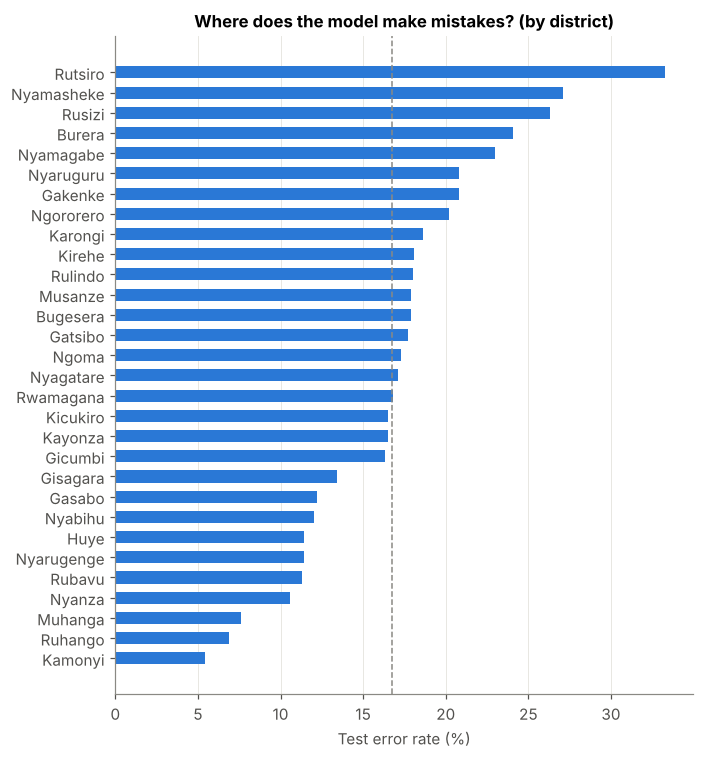

0.49 = correlation between a district's adoption rate and its error rate


In [19]:
errs = err_table("district").sort_values("error_rate")
fig, ax = plt.subplots(figsize=(6.5, 7))
ax.barh(errs.index, errs["error_rate"] * 100, color=CLASS_CLR["No"], height=0.6)
ax.axvline((ea.y != ea.pred).mean() * 100, color="#8a8984", ls="--", lw=1)
ax.set_xlabel("Test error rate (%)"); ax.set_title("Where does the model make mistakes? (by district)")
ax.grid(axis="y", visible=False); plt.tight_layout()
plt.savefig(FIG / "13_ml_error_by_district.png", bbox_inches="tight"); plt.show()
print(errs[["plots", "actual_rate", "error_rate"]].corr().round(2).loc["actual_rate", "error_rate"],
      "= correlation between a district's adoption rate and its error rate")

> ✍️ **Your interpretation:** Which provinces, districts or farmer types have the highest error rates? Are errors concentrated where adoption is close to 50% (the hardest districts to call), or somewhere else? Are missed users (false negatives) or false alarms (false positives) the bigger problem, and in which regions? What information is **missing** from the survey that might explain the errors? Think about input prices, distance to an agro-dealer, access to credit, soil quality, rainfall, and membership of a farmer cooperative.
>
> The western Province Has more error rate with 21.9%  and the lowest was Southern province with only error rate of 11.5%. and also we have correlation of 0.49 between a district’s fertilizer rate and its error rate. this shows the higher a district’s adoption, the more mistakes the model makes there.

### 11. Save the best model and results
- The full pipeline (preprocessing + model) is saved with **joblib**, so it can be loaded and used on raw feature columns directly. This file goes in the **Google Drive** folder (not GitHub, since `models/` is gitignored).
- The metrics are saved to `results/` so notebook 3 can build the final ML vs DL comparison table.

In [20]:
fname = MODELS / "best_traditional_ml.joblib"
joblib.dump({"pipeline": best_model, "threshold": thr, "model_name": BEST,
             "features": {"categorical": CAT, "numeric": NUM_FE, "binary": BIN}}, fname)
print(f"Saved {fname.name} ({fname.stat().st_size / 1e6:.1f} MB)")

results = {"selected_model": BEST, "threshold": thr,
           "test_metrics_selected": test_table.iloc[[list(tuned).index(BEST)]].iloc[0].to_dict(),
           "test_metrics_all": test_table.to_dict(orient="index"),
           "val_auc_tuned": val_auc,
           "best_params": {n: {k: (v if not isinstance(v, (np.floating, np.integer)) else v.item())
                               for k, v in s.best_params_.items()} for n, s in searches.items()}}
json.dump(results, open(RESULTS / "traditional_ml_results.json", "w"), indent=2, default=str)
pd.DataFrame({"plot_uid": test["plot_uid"], "y_true": y_te, "score": scores_of(best_model, X_te), "pred": y_pred_te}) \
  .to_csv(RESULTS / "traditional_ml_test_predictions.csv", index=False)
exp1.to_csv(RESULTS / "exp1_default_cv.csv"); exp2.to_csv(RESULTS / "exp2_balanced_cv.csv")
exp3.to_csv(RESULTS / "exp3_tuning_val.csv"); exp4.to_csv(RESULTS / "exp4_ablation_val.csv")
print("Saved results:", *sorted(p.name for p in RESULTS.iterdir()), sep="\n  ")

Saved best_traditional_ml.joblib (2.4 MB)
Saved results:
  exp1_default_cv.csv
  exp2_balanced_cv.csv
  exp3_tuning_val.csv
  exp4_ablation_val.csv
  traditional_ml_results.json
  traditional_ml_test_predictions.csv


### Summary
### Experiments
Class weights made the biggest difference in the experiments. They increased recall from around 60% to 80%, while ROC-AUC stayed almost unchanged. This means the models found more fertilizer users without becoming better at ranking plots. Before these changes, the majority-class baseline predicted “No” for every plot and achieved a ROC-AUC of 0.50. All four models performed much better, scoring between 0.881 and 0.897 in 5-fold farmer-grouped cross-validation. Hyperparameter tuning changed ROC-AUC by less than 0.002, so it offered little improvement. The ablation study showed that crops (−0.043), farming practices (−0.038) and location (−0.019) mattered most, while demographics and engineered farmer-level features added little. Pesticide use increased the score by 0.010, suggesting possible data leakage, so it was excluded. Raising the decision threshold from 0.50 to 0.57 slightly improved the balance between precision and recall.
### Final Model
Gradient Boosting was selected because it achieved the highest validation ROC-AUC. On the test set, it scored 0.892 ROC-AUC, 0.712 F1-score, 0.68 precision and 0.75 recall. It correctly identified 1,048 of 1,395 fertilizer-using plots but incorrectly flagged 499 of 3,650 plots that did not use fertilizer. The other models scored between 0.878 and 0.890, with nearly overlapping ROC curves. This suggests that the available data, rather than the algorithm, limits performance.
### Strengths and Limitations
Gradient Boosting showed mild overfitting, with a training-validation gap of 0.067, although its validation score was still rising slowly. Logistic Regression underfit because it could not capture feature interactions. Improved seed, Irish potato, organic fertilizer and district were the strongest predictors. This fits Rwanda’s agricultural context, where crops such as Irish potatoes in Musanze and Nyabihu are important, although the model alone cannot explain farmers’ fertilizer decisions. The Western Province had a 21.9% error rate, with fertilizer adoption closer to 50%. False alarms were more common where fertilizer use was high, while missed users were more common where it was rare. The dataset covers only one survey year, relies on self-reported answers and lacks factors such as soil quality, rainfall, fertilizer prices and credit access. Therefore, the findings show associations, not causes, and the model needs testing on data from other years.
**Next:** `03_deep_learning.ipynb` builds neural networks in TensorFlow/Keras with `tf.data` input pipelines on the same splits, and compares them with these results.